# 09 — Source-field audit and validation-data readiness

This notebook checks which source-native fields in the FIRMS extracts can support better candidate association and its independent validation. It reads only the normalized Parquet and preserves original values.

NASA field references: [MODIS FIRMS attributes](https://firms.modaps.eosdis.nasa.gov/content/descriptions/FIRMS_MODIS_Firehotspots.html), [VIIRS FIRMS attributes](https://firms.modaps.eosdis.nasa.gov/content/descriptions/FIRMS_VIIRS_Firehotspots.html). VIIRS C2 L2 swath documentation: [375 m User Guide](https://www.earthdata.nasa.gov/s3fs-public/2025-06/VIIRS_C2_AF-375m_User_Guide_1.2.pdf).


In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

ROOT=Path.cwd()
if not (ROOT/'data').exists() and (ROOT.parent/'data').exists(): ROOT=ROOT.parent
DATA=ROOT/'data'/'processed'/'observations.parquet'
COLS=['year_folder','product_code','stream_type','satellite','scan','track','scan_num','track_num','type','type_num','daynight','confidence','confidence_family','observation_datetime_utc']
obs=pd.read_parquet(DATA,columns=COLS)
print(f'{len(obs):,} rows across {obs.product_code.nunique()} product families')


1,130,027 rows across 4 product families


In [2]:
source_summary=(obs.groupby(['year_folder','product_code','stream_type','satellite'],dropna=False)
 .agg(records=('scan_num','size'),scan_missing=('scan_num',lambda x:int(x.isna().sum())),track_missing=('track_num',lambda x:int(x.isna().sum())),
      scan_p50_km=('scan_num','median'),scan_p95_km=('scan_num',lambda x:x.quantile(.95)),
      track_p50_km=('track_num','median'),track_p95_km=('track_num',lambda x:x.quantile(.95)),
      type_present=('type_num',lambda x:int(x.notna().sum())),valid_timestamps=('observation_datetime_utc',lambda x:int(x.notna().sum())))
 .reset_index())
display(source_summary.round(3))
print('Total missing scan:',int(obs.scan_num.isna().sum()),'| track:',int(obs.track_num.isna().sum()),'| type:',int(obs.type_num.isna().sum()))


,year_folder,product_code,stream_type,satellite,records,scan_missing,track_missing,scan_p50_km,scan_p95_km,track_p50_km,track_p95_km,type_present,valid_timestamps
0,2025,J1V-C2,archive,N20,224606,0.0,0.0,0.43,0.6,0.43,0.68,224606.0,224606
1,2025,J2V-C2,archive,N21,218188,0.0,0.0,0.43,0.61,0.44,0.69,218188.0,218188
2,2025,M-C61,archive,Aqua,35900,0.0,0.0,1.2,2.8,1.1,1.6,35900.0,35900
3,2025,M-C61,archive,Terra,6220,0.0,0.0,1.2,2.8,1.1,1.6,6220.0,6220
4,2025,SV-C2,archive,SNPP,227320,0.0,0.0,0.43,0.6,0.42,0.68,227320.0,227320
5,2026,J1V-C2,archive,N20,132632,0.0,0.0,0.43,0.6,0.42,0.67,132632.0,132632
6,2026,J1V-C2,near_real_time,N20,3640,0.0,0.0,0.42,0.57,0.42,0.64,0.0,3640
7,2026,J2V-C2,archive,N21,126367,0.0,0.0,0.43,0.61,0.44,0.7,126367.0,126367
8,2026,J2V-C2,near_real_time,N21,3332,0.0,0.0,0.44,0.61,0.47,0.7,0.0,3332
9,2026,M-C61,archive,Aqua,15938,0.0,0.0,1.1,2.6,1.1,1.6,15938.0,15938


Total missing scan: 0 | track: 0 | type: 10938


In [3]:
type_table=(obs.assign(type_label=obs.type.astype('string').fillna('<not supplied>'))
 .groupby(['product_code','stream_type','type_label'],dropna=False).size().rename('records').reset_index())
display(type_table)
print('day/night counts')
display(obs.groupby(['product_code','stream_type','daynight'],dropna=False).size().rename('records').reset_index())


,product_code,stream_type,type_label,records
0,J1V-C2,archive,0,356023
1,J1V-C2,archive,2,932
2,J1V-C2,archive,3,283
3,J1V-C2,near_real_time,<not supplied>,3640
4,J2V-C2,archive,0,343415
5,J2V-C2,archive,2,928
6,J2V-C2,archive,3,212
7,J2V-C2,near_real_time,<not supplied>,3332
8,M-C61,archive,0,60782
9,M-C61,archive,1,35


day/night counts


,product_code,stream_type,daynight,records
0,J1V-C2,archive,D,302313
1,J1V-C2,archive,N,54925
2,J1V-C2,near_real_time,D,3474
3,J1V-C2,near_real_time,N,166
4,J2V-C2,archive,D,291265
5,J2V-C2,archive,N,53290
6,J2V-C2,near_real_time,D,3149
7,J2V-C2,near_real_time,N,183
8,M-C61,archive,D,56291
9,M-C61,archive,N,4674


C:\Users\ngong\AppData\Local\Temp\ipykernel_9004\338755897.py:10: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  axes[0].boxplot([g.scan_num.dropna().astype(float) for g in samples],labels=satellites,showfliers=False)
C:\Users\ngong\AppData\Local\Temp\ipykernel_9004\338755897.py:12: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  axes[1].boxplot([g.track_num.dropna().astype(float) for g in samples],labels=satellites,showfliers=False)


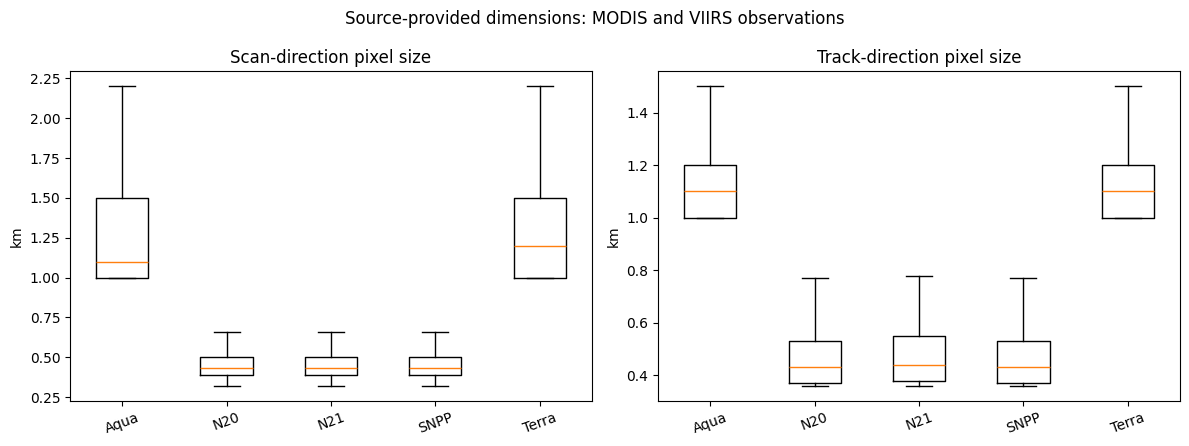

In [4]:
# Visualization uses a deterministic sample for responsiveness; summary table above uses every row.
rng=np.random.default_rng(20261114)
satellites=sorted(obs.satellite.dropna().unique())
samples=[]
for sat in satellites:
    group=obs.loc[obs.satellite.eq(sat),['scan_num','track_num']]
    if len(group)>20000: group=group.iloc[rng.choice(len(group),20000,replace=False)]
    samples.append(group)
fig,axes=plt.subplots(1,2,figsize=(12,4.5))
axes[0].boxplot([g.scan_num.dropna().astype(float) for g in samples],labels=satellites,showfliers=False)
axes[0].set_title('Scan-direction pixel size'); axes[0].set_ylabel('km')
axes[1].boxplot([g.track_num.dropna().astype(float) for g in samples],labels=satellites,showfliers=False)
axes[1].set_title('Track-direction pixel size'); axes[1].set_ylabel('km')
for ax in axes: ax.tick_params(axis='x',rotation=20)
fig.suptitle('Source-provided dimensions: MODIS and VIIRS observations')
fig.tight_layout(); plt.show()


## Interpretation and downstream decisions

The `scan`/`track` fields are fully populated and encode the actual pixel dimensions in kilometers, which vary with scan geometry. They can support a pixel-size-aware candidate-distance diagnostic. Since the CSV contains no pixel footprint orientation/vertices, a derived radius/overlap test would remain approximate; it must not be called exact footprint intersection. Keep the existing fixed-threshold evidence for comparison until any new method is evaluated.

`type` is absent only on NRT rows in this snapshot. Archive rows include type codes, but this is an algorithm-inferred class, not independent ground truth. Preserve it source-native and check the correct monthly product revision before applying codes, especially given NASA's documented VIIRS monthly-product Type-field reprocessing history.

For stronger coverage reasoning, NASA's VIIRS Collection 2 Level-2 swaths contain the full fire mask and same-grid algorithm QA; the mask distinguishes fire from cloud, land, water, unprocessed, and other classes. The FIRMS CSV alone includes detections, not all valid observed pixels. The next study should associate CSV points to granules, then build per-platform observed/valid-area masks before interpreting a missing cross-sensor detection. CMR metadata search confirms granules intersecting the demo bounding box, but metadata bounding boxes do not equal pixel-level coverage.

Independent temporal corroboration is available in EUMETSAT LSA SAF SEVIRI/MSG FRP-PIXEL (Africa; 3 km; 15 minutes). It can show whether broad fire activity persists near a polar-orbit overpass, but it is a different sensor/product and is not ground truth. Monthly MODIS/VIIRS burned-area products are a later, coarser corroboration option, not exact labels for active-fire observations.
